# Section 2: Protein Filtering

**Course: Protein Design — graduate practical**

Predict structures for three PLP-dependent alanine racemases, inspect pLDDT,
then compare their predicted solubility and turnover numbers for L-alanine.

**Workflow:** sequence CSV → ESMFold → pLDDT and structure visualization
→ GATSol solubility prediction → UniKP kcat prediction → compare results
→ InterPro functional annotation.

All three models use the same protein sequences and UniProt IDs.
UniKP also requires the substrate SMILES.


## 1. Paths and environment

Set the model paths before running the cells from top to bottom. Run this notebook
from the `tt2` directory so that relative input, script, and output paths resolve correctly.
ESMFold uses a local Hugging Face model directory; GATSol and ESM-1b use local `.pt` files.

The notebook kernel needs `torch`, `transformers`, `numpy`, `pandas`, `matplotlib`,
`biopython`, and `py3Dmol`. A GPU with sufficient memory is recommended.
The configuration cell below explains each parameter and how to adjust it.

The GATSol environment needs `torch`, `torch-geometric`, `fair-esm`, `biopython`, and
`numpy`. `fair-esm` provides the required `esm.pretrained` interface. If GATSol runs
in a separate environment, set `GATSOL_PYTHON` to that environment's Python executable.
Keep `esm1b_t33_650M_UR50S-contact-regression.pt` in the same directory as the ESM-1b checkpoint.

UniKP also requires `sentencepiece`, `scikit-learn`, `rdkit`, and `tqdm`.
The notebook kernel must support both ESMFold and UniKP; GATSol can run in a separate
Python environment. The local kcat checkpoint records scikit-learn version **0.24.2**.
Use an environment compatible with this pickle. A tree-node dtype incompatibility
error requires a scikit-learn version compatible with the older checkpoint.

UniKP uses `./UniKP/vocab.pkl`, `./UniKP/trfm_12_23000.pkl`, and
`./UniKP/UniKP for kcat.pkl`. The ProtT5 path is fixed in `UniKP/UniKP_kcat.py` as
`/data/home/xiongwen2/software/prot_t5_xl_uniref50`.


In [ ]:
import sys
import os
import gc
import json
import re
import subprocess

# Run from the tt2 directory. Input, script, and output paths are relative to it.
# Update the following model paths to match the files available on your server.

# Local Hugging Face ESMFold directory containing model configuration, tokenizer,
# and weights. Used to predict 3D structures; provide a directory, not a .pt file.
ESMFOLD_MODEL_DIR = "/data/home/xiongwen2/software/esmfold_v1"

# Trained GATSol checkpoint used by predict_sol.py to score solubility.
# Provide the full path to the best_model.pt file.
GATSOL_WEIGHTS = "/data/home/xiongwen2/software/GATSol/retrain_model/best_model.pt"

# Local ESM-1b checkpoint used to generate sequence embeddings for GATSol.
# Provide a .pt file, not a directory. Keep the companion contact-regression
# checkpoint in the same directory, as described above.
ESM1B_MODEL = "/data/home/xiongwen2/software/esm1b_t33_650M_UR50S.pt"

# Python executable used to launch predict_sol.py as a separate process.
# sys.executable uses the notebook's environment. To use another GATSol environment,
# replace it with that environment's full Python path, e.g. /path/to/env/bin/python.
GATSOL_PYTHON = sys.executable

# Device for GATSol only: "auto" chooses CUDA if available in its Python environment,
# otherwise CPU. Use "cpu" to force CPU or "cuda" to require a working CUDA GPU.
# ESMFold selects its own device in the next cell.
GATSOL_DEVICE = "auto"

# CSV containing the three full protein sequences and their UniProt IDs.
# All three models use these same sequences; UniProt IDs link their results.
# The default CSV is in tt2. To use new candidates, keep the same column names.
CANDIDATE_CSV = "./plp_sequences.csv"

# Chunk size for ESMFold's axial attention, not a sequence-length limit or batch size.
# Smaller values reduce memory use but can slow inference. If GPU memory is
# insufficient, try 32 or 16 instead of 64.
CHUNK_SIZE = 64

# Shared output directory for structures, pLDDT, scores, plots, logs, and FASTA.
# It is created automatically. Repeated runs overwrite files with the same names;
# choose a different directory if you want to preserve an earlier run.
OUTPUT_DIR = "./outputs/section2_protein_filtering"

# Optional: select a GPU here, before importing torch in the next cell.
# os.environ["CUDA_VISIBLE_DEVICES"] = "0"
print("Notebook Python:", sys.executable)
print("GATSol Python:", GATSOL_PYTHON)
print("Output:", OUTPUT_DIR)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
import py3Dmol
from IPython.display import display
from transformers import AutoTokenizer, EsmForProteinFolding
from transformers.models.esm.openfold_utils.feats import atom14_to_atom37
from transformers.models.esm.openfold_utils.protein import Protein as OFProtein, to_pdb

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "Transformers:", transformers.__version__)
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1))
else:
    print("Running on CPU; ESMFold is slow and requires substantial memory.")


## 2. Load three PLP-dependent enzymes

PLP (pyridoxal 5′-phosphate) is a small-molecule cofactor. These three proteins are
PLP-dependent **alanine racemases** from different organisms, with the same enzyme
function and comparable sequence lengths.

| UniProt ID | Organism | Residues |
|---|---|---:|
| [P10724](https://www.uniprot.org/uniprotkb/P10724/entry) | Geobacillus stearothermophilus | 388 |
| [P0A6B4](https://www.uniprot.org/uniprotkb/P0A6B4/entry) | Escherichia coli (K12) | 359 |
| [P10725](https://www.uniprot.org/uniprotkb/P10725/entry) | Bacillus subtilis (168) | 389 |

`plp_sequences.csv` contains full UniProt canonical sequences, protein names,
organisms, source URLs, and sequence MD5 checksums. UniProt IDs are retained in
the prediction filenames and score tables. These are natural enzyme sequences,
used here as candidates for the filtering exercise.

All three models use the three full sequences in the CSV. UniProt IDs link all results.


In [ ]:
# Load the three sequences; use UniProt IDs for filenames and to link results.
candidates = pd.read_csv(CANDIDATE_CSV)
candidates["sequence"] = candidates["sequence"].str.replace(r"\s+", "", regex=True).str.upper()
candidates["length"] = candidates["sequence"].str.len()
display(candidates[["uniprot_id", "protein_name", "organism", "length"]])

os.makedirs(OUTPUT_DIR, exist_ok=True)
for folder in ["structures", "residue_metrics", "figures", "logs"]:
    os.makedirs(f"{OUTPUT_DIR}/{folder}", exist_ok=True)
candidates.to_csv(f"{OUTPUT_DIR}/candidates.csv", index=False)


### GATSol runtime configuration

Models are loaded directly from the configured local paths.

For trusted local checkpoints, legacy fair-esm needs compatibility with the
`torch.load` defaults in PyTorch 2.6+. The environment variables below apply
only to the GATSol subprocess.


In [ ]:
# Set legacy ESM-1b checkpoint loading and output encoding for the GATSol subprocess.
gatsol_env = os.environ.copy()
gatsol_env["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"
gatsol_env["PYTHONIOENCODING"] = "utf-8"

run_config = {
    "esmfold_model_dir": ESMFOLD_MODEL_DIR,
    "gatsol_weights": GATSOL_WEIGHTS,
    "esm1b_model": ESM1B_MODEL,
    "notebook_python": sys.executable, "gatsol_python": GATSOL_PYTHON,
    "gatsol_device": GATSOL_DEVICE,
    "torch_version": torch.__version__, "transformers_version": transformers.__version__,
    "device": DEVICE, "chunk_size": CHUNK_SIZE,
    "candidate_csv": CANDIDATE_CSV,

}
with open(f"{OUTPUT_DIR}/run_config.json", "w", encoding="utf-8") as handle:
    json.dump(run_config, handle, indent=2)


## 3. ESMFold: predict structures and inspect pLDDT

ESMFold predicts protein coordinates directly from a sequence, without requiring
a multiple-sequence alignment. It also estimates local prediction confidence.

**pLDDT** is reported here on a 0–100 scale. Higher scores indicate greater local
confidence; a high mean can hide a low-confidence loop or terminus. pLDDT does not
measure solubility or enzyme activity. ESMFold predicts the protein chain, not its PLP cofactor.

Predict one sequence at a time and load the model only once. Save the PDB,
per-residue pLDDT, and mean pLDDT for each sequence. The PDB B-factor column
also stores pLDDT on the 0–100 scale.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(ESMFOLD_MODEL_DIR, local_files_only=True)
fold_model = EsmForProteinFolding.from_pretrained(
    ESMFOLD_MODEL_DIR, local_files_only=True,
).eval().to(DEVICE)
fold_model.trunk.set_chunk_size(CHUNK_SIZE)


@torch.inference_mode()
def fold_one(sequence, pdb_path):
    """Run model inference, return C-alpha pLDDT, and save the full predicted structure."""
    tokens = tokenizer([sequence], return_tensors="pt", add_special_tokens=False)["input_ids"].to(DEVICE)
    output = fold_model(tokens)
    atom_positions = atom14_to_atom37(output["positions"][-1], output)[0].cpu().numpy()
    atom_mask = output["atom37_atom_exists"][0].cpu().numpy()
    plddt = output["plddt"][0].cpu().numpy()
    # Convert pLDDT to the 0–100 scale if the model returns values on a 0–1 scale.
    if plddt.max() <= 1.0:
        plddt = plddt * 100.0
    protein = OFProtein(
        aatype=output["aatype"][0].cpu().numpy(),
        atom_positions=atom_positions,
        atom_mask=atom_mask,
        residue_index=output["residue_index"][0].cpu().numpy() + 1,
        b_factors=plddt,
    )
    with open(pdb_path, "w", encoding="utf-8") as handle:
        handle.write(to_pdb(protein))
    ca_plddt = plddt[:, 1].copy()  # Index 1 in atom37 corresponds to C-alpha.
    del tokens, output
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return ca_plddt

Some weights of EsmForProteinFolding were not initialized from the model checkpoint at /data/home/xiongwen2/software/esmfold_v1 and are newly initialized: ['esm.contact_head.regression.bias', 'esm.contact_head.regression.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [7]:
structure_rows = []
for row in candidates.itertuples(index=False):
    print(f"ESMFold: {row.uniprot_id}, {row.length} residues", flush=True)
    pdb_path = f"{OUTPUT_DIR}/structures/{row.uniprot_id}.pdb"
    ca_plddt = fold_one(row.sequence, pdb_path)
    residue_table = pd.DataFrame({
        "position": np.arange(1, row.length + 1),
        "amino_acid": list(row.sequence), "plddt": ca_plddt,
    })
    residue_table.to_csv(f"{OUTPUT_DIR}/residue_metrics/{row.uniprot_id}.csv", index=False)
    structure_rows.append({
        "uniprot_id": row.uniprot_id, "pdb_path": pdb_path,
        "mean_plddt": float(ca_plddt.mean()),
        "fraction_plddt_below_70": float((ca_plddt < 70).mean()),
    })
    # Save after each prediction to retain completed results if a later step fails.
    pd.DataFrame(structure_rows).to_csv(f"{OUTPUT_DIR}/esmfold_scores.csv", index=False)

structure_scores = pd.DataFrame(structure_rows)
display(structure_scores.round(3))

# Release the ESMFold model before running GATSol.
del fold_model, tokenizer
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

ESMFold: P10724, 388 residues
ESMFold: P0A6B4, 359 residues
ESMFold: P10725, 389 residues


,uniprot_id,pdb_path,mean_plddt,fraction_plddt_below_70
0,P10724,./outputs/section2_protein_filtering/structure...,89.762,0.036
1,P0A6B4,./outputs/section2_protein_filtering/structure...,93.757,0.003
2,P10725,./outputs/section2_protein_filtering/structure...,91.651,0.033


### View confidence profiles and predicted structures

Inspect all three structures before calculating solubility. Compare the locations
of low-confidence regions, not only the mean pLDDT. The plots are saved as PNG,
and each rotatable structure view is saved as HTML.

In [ ]:
# Plot per-residue pLDDT for each of the three sequences.
fig, ax = plt.subplots(figsize=(10, 4))
for row in structure_scores.itertuples(index=False):
    table = pd.read_csv(f"{OUTPUT_DIR}/residue_metrics/{row.uniprot_id}.csv")
    ax.plot(table["position"], table["plddt"], label=row.uniprot_id)
ax.axhline(70, color="gray", linestyle="--", linewidth=1)
ax.set(xlabel="Sequence position", ylabel="Cα pLDDT", ylim=(0, 100))
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figures/plddt_profiles.png", dpi=180, bbox_inches="tight")
plt.show()

def save_structure_view(pdb_path, html_path):
    """Save a rotatable structure view colored by pLDDT on the 0–100 scale."""
    view = py3Dmol.view(width=800, height=500)
    with open(pdb_path, encoding="utf-8") as handle:
        view.addModel(handle.read(), "pdb")
    view.setStyle({"cartoon": {"colorscheme": {
        "prop": "b", "gradient": "roygb", "min": 0, "max": 100,
    }}})
    view.setBackgroundColor("white")
    view.zoomTo()
    with open(html_path, "w", encoding="utf-8") as handle:
        handle.write(view.write_html())
    return view


# Save and display all three predicted structures using their UniProt IDs.
for row in structure_scores.itertuples(index=False):
    print(f"{row.uniprot_id}: mean pLDDT = {row.mean_plddt:.1f}")
    print("pLDDT colors: low = red, high = blue")
    view = save_structure_view(
        row.pdb_path, f"{OUTPUT_DIR}/figures/{row.uniprot_id}_plddt.html",
    )
    view.show()


## 4. GATSol: predict solubility and rank the three proteins

GATSol builds a Cα contact graph from the structure and combines BLOSUM62 encodings
with ESM-1b sequence embeddings. Graph attention layers produce a solubility score.

Pass each sequence and its ESMFold PDB to `predict_sol.py`. Rank higher `sol` scores
first. These are regression scores, not calibrated probabilities. Low-confidence
input structures may affect the solubility predictions.

Use the matching predicted PDB for each sequence. Keep UniProt IDs in the logs,
score tables, and final ranking.

In [11]:
def score_gatsol(sequence, pdb_path, uniprot_id):
    """Call predict_sol.py with the sequence and predicted PDB of the same candidate."""
    command = [
        GATSOL_PYTHON, "./predict_sol.py", sequence, pdb_path,
        "--weights", GATSOL_WEIGHTS, "--esm-model", ESM1B_MODEL,
        "--device", GATSOL_DEVICE,
    ]
    completed = subprocess.run(
        command, cwd=".", env=gatsol_env,
        capture_output=True, text=True, encoding="utf-8",
    )
    log_path = f"{OUTPUT_DIR}/logs/{uniprot_id}_gatsol.txt"
    with open(log_path, "w", encoding="utf-8") as handle:
        handle.write(completed.stdout + "\n" + completed.stderr)
    if completed.returncode:
        raise RuntimeError("GATSol failed:\n" + (completed.stderr or completed.stdout))
    match = re.search(r"^sol\s*=\s*([-+0-9.eE]+)\s*$", completed.stdout, re.MULTILINE)
    return float(match.group(1))


evaluation = candidates.merge(structure_scores, on="uniprot_id")
gatsol_rows = []
for row in evaluation.itertuples(index=False):
    print("GATSol:", row.uniprot_id, flush=True)
    score = score_gatsol(row.sequence, row.pdb_path, row.uniprot_id)
    gatsol_rows.append({"uniprot_id": row.uniprot_id, "sol": score})
    pd.DataFrame(gatsol_rows).to_csv(f"{OUTPUT_DIR}/gatsol_scores.csv", index=False)

ranked = evaluation.merge(pd.DataFrame(gatsol_rows), on="uniprot_id")
ranked = ranked.sort_values("sol", ascending=False, kind="stable").reset_index(drop=True)
ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
ranked.to_csv(f"{OUTPUT_DIR}/ranked_candidates.csv", index=False)
display(ranked[["rank", "uniprot_id", "protein_name", "length", "sol",
                "mean_plddt", "fraction_plddt_below_70"]].round(3))

GATSol: P10724
GATSol: P0A6B4
GATSol: P10725


,rank,uniprot_id,protein_name,length,sol,mean_plddt,fraction_plddt_below_70
0,1,P0A6B4,"Alanine racemase, biosynthetic",359,0.428,93.757,0.003
1,2,P10725,Alanine racemase 1,389,0.420,91.651,0.033
2,3,P10724,Alanine racemase,388,0.316,89.762,0.036


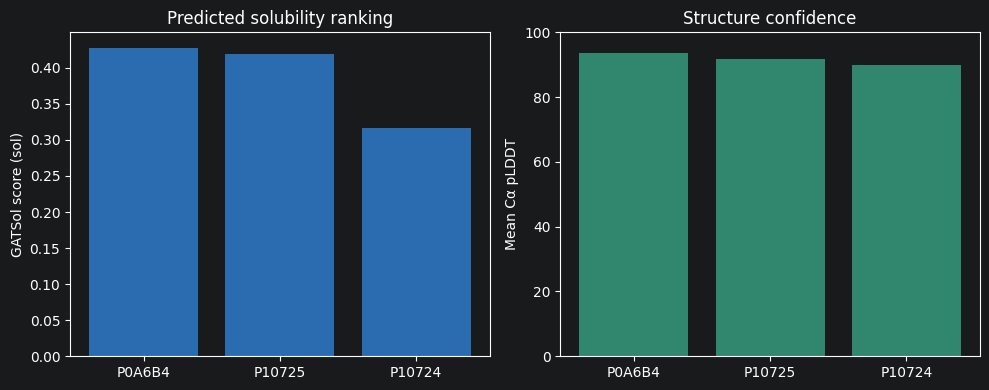

In [12]:
# Plot solubility scores and mean structural confidence separately.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(ranked["uniprot_id"], ranked["sol"], color="#2b6cb0")
axes[0].set(ylabel="GATSol score (sol)", title="Predicted solubility ranking")
axes[1].bar(ranked["uniprot_id"], ranked["mean_plddt"], color="#31876d")
axes[1].set(ylabel="Mean Cα pLDDT", ylim=(0, 100), title="Structure confidence")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figures/ranking_and_confidence.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. UniKP: principle and protein–substrate inputs

**kcat** is the number of catalytic turnovers per active site per second at substrate
saturation. UniKP combines a **ProtT5 protein representation** with a **SMILES Transformer
substrate representation** and predicts log10(kcat) using an Extra Trees regressor.
The `predict_kcat()` function converts the prediction back to kcat in **s⁻¹**.

The three proteins are alanine racemases: **P10724, P0A6B4, and P10725**. Their substrate
is **L-alanine**, while **PLP is a cofactor**. Use the substrate SMILES, rather than the
SMILES of PLP, for the L-alanine → D-alanine reaction.

L-alanine SMILES: **`C[C@@H](C(=O)O)N`** (neutral form, with stereochemistry).

Sources: [UniKP](https://github.com/Luo-SynBioLab/UniKP),
[L-alanine, PubChem CID 5950](https://pubchem.ncbi.nlm.nih.gov/compound/L-alanine),
[P10724](https://www.uniprot.org/uniprotkb/P10724/entry),
[P0A6B4](https://www.uniprot.org/uniprotkb/P0A6B4/entry),
[P10725](https://www.uniprot.org/uniprotkb/P10725/entry).


In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

# Import the prediction function from the local UniKP directory.
sys.path.insert(0, "./UniKP")
from UniKP_kcat import predict_kcat

SUBSTRATE_NAME = "L-alanine"
SUBSTRATE_SMILES = "C[C@@H](C(=O)O)N"

# Pair each of the three previously loaded sequences with the same substrate.
unikp_inputs = candidates.copy()
unikp_inputs["substrate_name"] = SUBSTRATE_NAME
unikp_inputs["substrate_smiles"] = SUBSTRATE_SMILES
unikp_inputs.to_csv(f"{OUTPUT_DIR}/unikp_inputs.csv", index=False)
display(unikp_inputs[["uniprot_id", "organism", "substrate_name", "substrate_smiles"]])

# Display and save the chemical structure of L-alanine.
substrate_mol = Chem.MolFromSmiles(SUBSTRATE_SMILES)
substrate_image = Draw.MolToImage(substrate_mol, size=(400, 250))
substrate_image.save(f"{OUTPUT_DIR}/figures/L_alanine.png")
display(substrate_image)


## 6. UniKP: predict kcat and compare results

Predict one protein–substrate pair at a time. The models are loaded on the first
call and reused for subsequent sequences. `predict_kcat()` already returns
kcat in **s⁻¹**; no additional exponentiation is needed.

Higher predicted kcat suggests faster turnover for L-alanine. Compare it with
solubility and structural confidence when choosing proteins for experiments.
These predictions do not include assay temperature, pH, or PLP occupancy.


In [ ]:
# Predict one pair at a time; load models on the first call and reuse them afterward.
import warnings

# Suppress warnings during prediction while keeping results and exceptions visible.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    kcat_values = []
    for row in unikp_inputs.itertuples(index=False):
        kcat = predict_kcat([row.sequence], [row.substrate_smiles])[0]
        kcat_values.append(kcat)
        print(f"{row.uniprot_id}: {kcat:.3g} s^-1")

# Save predictions in input order, then rank them by decreasing kcat.
kcat_results = unikp_inputs.copy()
kcat_results["kcat_s_inv"] = kcat_values
kcat_results.to_csv(f"{OUTPUT_DIR}/unikp_kcat_predictions.csv", index=False)

kcat_ranked = kcat_results.sort_values("kcat_s_inv", ascending=False).reset_index(drop=True)
kcat_ranked.insert(0, "kcat_rank", range(1, len(kcat_ranked) + 1))
kcat_ranked.to_csv(f"{OUTPUT_DIR}/unikp_kcat_ranked.csv", index=False)
display(kcat_ranked[["kcat_rank", "uniprot_id", "organism", "substrate_name", "kcat_s_inv"]])


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(kcat_ranked["uniprot_id"], kcat_ranked["kcat_s_inv"], color="#2b6cb0")
ax.set_yscale("log")
ax.set_xlabel("UniProt ID")
ax.set_ylabel("Predicted kcat (s⁻¹, log scale)")
ax.set_title("UniKP predictions for L-alanine")
for index, value in enumerate(kcat_ranked["kcat_s_inv"]):
    ax.annotate(f"{value:.3g}", (index, value), xytext=(0, 5),
                textcoords="offset points", ha="center")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/figures/unikp_kcat_ranking.png", dpi=180, bbox_inches="tight")
plt.show()


In [ ]:
# Merge results by UniProt ID and keep separate solubility and kcat rankings.
filtering_results = ranked.rename(columns={"rank": "sol_rank"}).merge(
    kcat_ranked[["uniprot_id", "substrate_name", "substrate_smiles", "kcat_s_inv", "kcat_rank"]],
    on="uniprot_id",
)
filtering_results.to_csv(f"{OUTPUT_DIR}/protein_filtering_results.csv", index=False)
display(filtering_results[["uniprot_id", "organism", "mean_plddt", "sol", "sol_rank",
                           "substrate_name", "kcat_s_inv", "kcat_rank"]].round(3))


## 7. InterPro: check the expected protein function

InterPro uses sequence signatures to identify protein families, domains, and
functional sites. Compare these annotations with the function you want to retain.
For these three candidates, the expected function is **PLP-dependent alanine racemase**.
Sequence annotations support a functional hypothesis; experimental assays are needed
to confirm activity.

Export the same three sequences as FASTA, then submit them through the website.
No additional model installation is required.


In [ ]:
# Export the same candidates and retain UniProt IDs to link annotations with scores.
fasta_text = "".join(
    f">{row.uniprot_id}\n{row.sequence}\n"
    for row in candidates.itertuples(index=False)
)
fasta_file = f"{OUTPUT_DIR}/interpro_candidates.fasta"
with open(fasta_file, "w", encoding="utf-8") as handle:
    handle.write(fasta_text)

print("FASTA saved:", fasta_file)
print(fasta_text)


### Submit the sequences and inspect the annotations

1. Open the [InterPro sequence search page](https://www.ebi.ac.uk/interpro/sequencesearch).
2. Paste the FASTA text printed above or upload `interpro_candidates.fasta`.
   Submit all three sequences together and select **Protein / amino acids** as the sequence type.
3. Start the search and wait for the analysis to finish. View each result using its UniProt ID.
4. Inspect **protein family** and **domain** entries for support of alanine racemase function.
   Open the matching entries, read their descriptions, and check domain positions and coverage.
5. If functional sites or GO annotations are available, check whether they support the
   intended catalytic function. PLP-binding annotations can provide supporting evidence;
   consider them together with the specific protein family and domains.
6. Download the result table. Record each sequence's InterPro entry IDs, names,
   domain positions, and your functional interpretation. Compare these findings with
   pLDDT, solubility, and kcat predictions.

A missing match does not prove loss of function. A family match alone does not
establish catalytic activity under specific experimental conditions.

Instructions: [InterPro official sequence search tutorial](https://www.ebi.ac.uk/training/online/courses/interpro-functional-and-structural-analysis/how-to-search-interpro/sequence-searching/).
